# Laplace Transform - Class Examples

In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
# Course utilities (do not modify this cell)
# Generated by post-canvas-notebooks. Edits above the marker are overwritten.
from pathlib import Path
import sys


def _find_courseutils():
    """Find courseutils no matter where the course repo was cloned."""
    here = Path.cwd().resolve()

    for parent in [here] + list(here.parents):
        for candidate in (parent / "courseutils",
                          parent / "Signals_and_Systems" / "courseutils"):
            if (candidate / "basic_material.py").is_file():
                return candidate.resolve()

    raise FileNotFoundError(
        "Could not find the 'courseutils' folder. Clone "
        "https://github.com/mit-acl/Signals_and_Systems and run this "
        "notebook from inside the cloned repository, then restart the kernel."
    )


COURSEUTILS_DIR = _find_courseutils()

# courseutils is used both as a folder of modules and as a package,
# since control_materials does "import courseutils.basic_material",
# so the folder and its parent both go on the path.
for _location in (COURSEUTILS_DIR.parent, COURSEUTILS_DIR):
    if str(_location) not in sys.path:
        sys.path.insert(0, str(_location))

for _folder in ("data", "figs"):
    Path(_folder).mkdir(exist_ok=True)

# --- end course setup ---

import basic_material as bm
print("Basic Material version:", bm.__version__)
bm.setup_environment()

Basic Material version: 16.002-0.1


In [3]:
colors = bm.get_colors()
import numpy as np
import matplotlib.pyplot as plt

import sympy as sympy
from sympy import Abs
from sympy.integrals.transforms import laplace_transform
from sympy.integrals.transforms import inverse_laplace_transform
from sympy.abc import a, t, x, s, X, g, G
print("Sympy version "+sympy.__version__)
sympy.init_printing(use_unicode=True)

a, x, g, X, G, tau = sympy.symbols('a x g X G tau', cls = sympy.Function)

Sympy version 1.13.3


In [4]:
# small positive time
t0p = 0+np.finfo(float).eps

## Circuit example from class

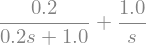

In [5]:
x0 = 2
RC = 1/5
W = laplace_transform(sympy.Heaviside(t,0), t, s, noconds = True)

eom = sympy.Eq((s*X(s)-x0) + X(s)/RC, W/RC)
Xofs = sympy.solve(eom,X(s)) 
Xofs[0].apart()

In [6]:
y_soln = inverse_laplace_transform(Xofs[0],s,t)
y_soln

In [7]:
y0_pos = y_soln.subs(t,t0p) 
print(f'IC expected to be {x0:.2f} and is {y0_pos:.2f}')

IC expected to be 2.00 and is 2.00


## Example 3 in Rec 7

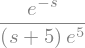

In [8]:
X = laplace_transform(sympy.exp(-5*t)*sympy.Heaviside(t-1), t, s, noconds = True)
X

## Example 2 in Rec 7

In [9]:
g = sympy.exp(-1*sympy.Abs(t))
g

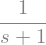

In [10]:
X = laplace_transform(g, t, s, noconds = True)
X

## 3rd order systems

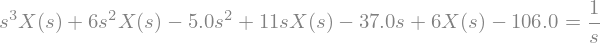

In [11]:
x, g, X =sympy.symbols('x g X', cls = sympy.Function)

x0 = 5.0 
v0 = 7.0
a0 = 9.0

a = 1
b = 6
c = 11
d = 6
W = laplace_transform(sympy.Heaviside(t,0), t, s, noconds = True)
eom  = sympy.Eq(a*(X(s)*s**3 - s**2*x0 - s*v0 - a0) + b*(s**2 *X(s)- s*x0 - v0) + c*(s*X(s) - x0) + d * X(s), W)
eom.replace(sympy.Heaviside(0), 0)

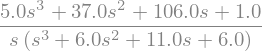

In [12]:
Xofs = sympy.solve(eom,X(s))[0]
Xofs

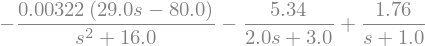

In [30]:
sympy.N(Xofs.apart(),3)

In [14]:
sympy.expand((s+1)*(s+2)*(s+3))

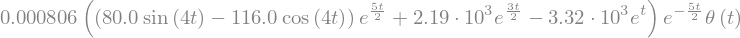

In [31]:
x_soln = inverse_laplace_transform(Xofs.apart(),s,t)
sympy.N(x_soln.simplify(),3)

In [16]:
n,d=sympy.fraction(Xofs)
6*n.subs(s,-3)/-3/-2/-1

In [17]:
print(f'{x_soln.subs(t,t0p):.2f}')

5.00


In [18]:
print(f'{x_soln.diff().subs(t,t0p):.2f}')

7.00


In [19]:
print(f'{x_soln.diff().diff().subs(t,t0p):.2f}')

9.00


## Example 5 in Topic 13

In [20]:
y, g, Y =sympy.symbols('y g Y', cls = sympy.Function)

# not give, so assume
y0_minus = 1 

a = 1
W = laplace_transform(sympy.Heaviside(t,1), t, s, noconds = True)
eom  = sympy.Eq(a*(s*Y(s) - y0_minus) + 1 * Y(s), 3*W)
Yofs = sympy.solve(eom,Y(s))[0]
Yofs
y_soln = inverse_laplace_transform(Yofs.apart(),s,t)
y_soln.simplify()

In [21]:
print(f'Expected IC(0+) are {y0_minus:.2f} and got {y_soln.subs(t,t0p):.2f}')

Expected IC(0+) are 1.00 and got 1.00


## Example 6 in Topic 13

In [22]:
x, g, X =sympy.symbols('x g X', cls = sympy.Function)

x0_minus = 0 
xdot0_minus = 1

a = 2
b = 7
c = 3
d = 1
W = laplace_transform(sympy.DiracDelta(t), t, s, noconds = True)
eom  = sympy.Eq(a*(s**2 *X(s)- s*x0_minus - xdot0_minus) + b*(s*X(s) - x0_minus) + c * X(s), d*W)

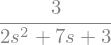

In [23]:
Xofs = sympy.solve(eom,X(s))[0]
Xofs

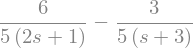

In [24]:
Xofs.apart()

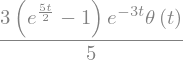

In [25]:
x_soln = inverse_laplace_transform(Xofs.apart(),s,t)
x_soln.simplify()

In [26]:
print(f'Expected IC(0+) are {x0_minus:.2f} and got {x_soln.subs(t,t0p):.2f}')

Expected IC(0+) are 0.00 and got 0.00


In [27]:
print(f'Expected IC(0+) are {xdot0_minus + d/a :.2f} and got {x_soln.diff().subs(t,t0p):.2f}')

Expected IC(0+) are 1.50 and got 1.50


## ODE/Integral

In [28]:
eom  = sympy.Eq(2*(s*X(s) - 1) + 5*X(s) + 3 * X(s)/s + 4 , 4/(s**2+16))

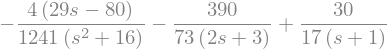

In [29]:
Xofs = sympy.solve(eom,X(s))[0]
Xofs.apart()